# Bangkok Airbnb Listings (Data Cleaning and EDA)


**Source:** Inside Airbnb, Bangkok `listings.csv` (snapshot: 23/09/2026)
**Goal:** Clean the raw listings data and explore it before the SQL analysis and Power BI dashboard.
**Output:** `listings_clean.csv` (used in SQL and Power BI) and `neighbourhood_summary.csv`.

In [81]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [82]:
import pandas as pd

# Path to the raw Inside Airbnb file. Change it if you run the notebook outside Google Drive.
file_path = "/content/drive/MyDrive/Portofolio/listings.csv"

df = pd.read_csv(file_path)

In [83]:
df.head(5)

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,27934,Nice room with superb city view,120437,1.462510e+18,Nuttee,NaN,Ratchathewi,13.75983,100.54134,Entire home/apt,1573.0,30.0,65,2024-09-17,0.38,1,362,0,NaN
1,47516,Beautiful waterfront house,214456,1.462513e+18,Anuradha,NaN,Don Mueang,13.92726,100.58529,Entire home/apt,NaN,3.0,0,NaN,NaN,1,365,0,NaN
2,48736,Condo with Chaopraya River View,222005,1.462513e+18,Athitaya,NaN,Rat Burana,13.68556,100.49535,Private room,1949.0,7.0,1,2014-02-03,0.01,1,365,0,NaN
3,55681,Sathorn Terrace Apartment(61),263049,1.462514e+18,Tor,NaN,Bang Rak,13.71934,100.51760,Private room,2368.0,2.0,44,2026-04-15,0.24,4,337,6,NaN
4,105042,Central Bangkok 3 Bedroom Apartment,545890,1.462521e+18,Henry,NaN,Khlong Toei,13.73378,100.56303,Entire home/apt,4326.0,28.0,147,2020-01-07,0.82,1,332,0,NaN


In [84]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31069 entries, 0 to 31068
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              31069 non-null  int64  
 1   name                            31069 non-null  object 
 2   host_id                         31069 non-null  int64  
 3   host_profile_id                 31067 non-null  float64
 4   host_name                       31069 non-null  object 
 5   neighbourhood_group             0 non-null      float64
 6   neighbourhood                   31069 non-null  object 
 7   latitude                        31069 non-null  float64
 8   longitude                       31069 non-null  float64
 9   room_type                       31069 non-null  object 
 10  price                           28987 non-null  float64
 11  minimum_nights                  31067 non-null  float64
 12  number_of_reviews               

In [85]:
df.shape

(31069, 19)

In [86]:
df.nunique()

,0
id,31069
name,28623
host_id,7935
host_profile_id,7935
host_name,6134
neighbourhood_group,0
neighbourhood,50
latitude,21247
longitude,22048
room_type,4


# Data Cleaning


In [87]:
df["last_review"].dropna().head(10)

,last_review
0,2024-09-17
2,2014-02-03
3,2026-04-15
4,2020-01-07
6,2024-04-15
7,2026-06-24
8,2025-08-22
10,2026-01-29
12,2019-08-04
13,2025-02-13


In [88]:
# Convert last_review to datetime
df["last_review"] = pd.to_datetime(
    df["last_review"],
    errors="coerce"
)


In [89]:
df["last_review"].dtype

dtype('<M8[ns]')

In [90]:
df.isnull().sum().sort_values(ascending=False)

,0
neighbourhood_group,31069
license,31069
reviews_per_month,10253
last_review,10253
price,2082
host_profile_id,2
minimum_nights,2
host_id,0
name,0
id,0


In [91]:
# Drop columns that are 100% empty (neighbourhood_group, license)
df.drop(columns=['neighbourhood_group', 'license'], inplace=True)

In [92]:
# Shape after dropping the empty columns
df.shape

(31069, 17)

In [93]:
df[
    (df["reviews_per_month"].isna()) &
    (df["number_of_reviews"] != 0)
]

,id,name,host_id,host_profile_id,host_name,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm


In [94]:
# Fill missing reviews_per_month with 0 (listings never reviewed)
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

In [95]:
df["reviews_per_month"].isna().sum()

np.int64(0)

In [96]:
(df["reviews_per_month"] == 0).sum()

np.int64(10253)

In [97]:
df[df["reviews_per_month"] == 0][
    ["number_of_reviews", "reviews_per_month", "last_review"]
].head()

,number_of_reviews,reviews_per_month,last_review
1,0,0.0,NaT
5,0,0.0,NaT
9,0,0.0,NaT
11,0,0.0,NaT
27,0,0.0,NaT


In [98]:
print(df["price"].isna().mean() * 100)
print(df[df["price"].isna()]["room_type"].value_counts())
print(df[df["price"].isna()]["neighbourhood"].value_counts().head(10))

6.701213428175995
room_type
Entire home/apt    1500
Private room        550
Hotel room           18
Shared room          14
Name: count, dtype: int64
neighbourhood
Vadhana         326
Khlong Toei     281
Huai Khwang     217
Ratchathewi     132
Sathon          100
Suanluang        88
Bang Na          85
Phra Khanong     83
Bang Rak         82
Chatu Chak       71
Name: count, dtype: int64


In [99]:
# host_profile_id is redundant: host_id already identifies the host
df.drop(columns=["host_profile_id"], inplace=True)

# Drop only rows with a missing minimum_nights, then cast it to int
df.dropna(subset=["minimum_nights"], inplace=True)

df["minimum_nights"] = df["minimum_nights"].astype("int64")

In [100]:
missing_pct = df.groupby("room_type")["price"].apply(lambda x: x.isna().mean() * 100)
print(missing_pct)

room_type
Entire home/apt    7.211885
Hotel room         6.143345
Private room       5.812110
Shared room        2.734375
Name: price, dtype: float64


In [101]:
# Inspect listings with minimum_nights > 365 before deciding how to treat them (flagged later, not removed)
df[df["minimum_nights"] > 365][["name", "room_type", "minimum_nights", "availability_365"]]

,name,room_type,minimum_nights,availability_365
138,Condominium 190 m2,Private room,729,263
257,NEW 65Sqm 2BD 2BR Sukhumvit26 Emquartier Emporium,Entire home/apt,370,364
422,Hip luxury cosy sukhumvit61 BTS Ekkamai 1bed,Entire home/apt,730,364
2429,Cozy 2BR/WIFI/POOL/BTSThonglor-Hippest District.,Entire home/apt,400,151
3078,NEW! COZY ROOM WITH RIVER VIEW,Private room,730,0
4447,Wonderful apartment for you holiday in Thai,Entire home/apt,1115,357
5550,blossom condo舒适双床房摩天轮夜市周边免费泳池健身房@Sathon surasa...,Entire home/apt,1000,179
6122,Luxury Private Condo with perfect atmosphere,Entire home/apt,500,364
8904,Luxury Condo in Khet Khlong Toei,Private room,730,360
8934,Comfortable apt near MRT Ratchadaphisek,Entire home/apt,600,365


In [102]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 31067 entries, 0 to 31068
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              31067 non-null  int64         
 1   name                            31067 non-null  object        
 2   host_id                         31067 non-null  int64         
 3   host_name                       31067 non-null  object        
 4   neighbourhood                   31067 non-null  object        
 5   latitude                        31067 non-null  float64       
 6   longitude                       31067 non-null  float64       
 7   room_type                       31067 non-null  object        
 8   price                           28985 non-null  float64       
 9   minimum_nights                  31067 non-null  int64         
 10  number_of_reviews               31067 non-null  int64         
 11  last_re

In [103]:
# Find names with leading or trailing whitespace
mask_whitespace = df["name"].apply(lambda x: x != x.strip())

# Show the affected rows
df[mask_whitespace][["name"]]

df[mask_whitespace]["name"].apply(lambda x: repr(x))

,name
11473,'Ekkamai八卧别墅by\xa0ThaiMe\xa0Villa\xa0泰蜜\xa0'
26942,'曼谷\xa0素坤逸S3别墅\n泰国星辰Stellar民宿\xa0\xa0'
27011,'\xa0【187】海天盛筵曼谷市中心独栋五房泳池别墅，近贵妇商场/四面佛/素坤逸街区'
29853,'RGBN 公寓丨开间-WiFi-健身房-泳池\xa0-C12F\xa0'
29856,'RGBN 公寓丨开间-WiFi-健身房-泳池-C19F\xa0'
29925,'RGWTK 公寓丨WiFi-健身房-泳池-独立阳台-拎包入住-A15F\xa0'
30335,'The Livin 丨市中心 -一卧-健身房-泳池-高速WiFi-超值-9FL\xa0'
30385,'The Livin 丨 超值-一卧-健身房-泳池-高速WiFi-市中心-37FL\xa0'
30387,'The Livin 丨市中心 -健身房-超值-一卧-泳池-高速WiFi-39FL\xa0\...
30388,'The Livin 丨市中心 -超值-健身房-泳池-高速WiFi-一卧-A栋\xa020F...


In [104]:
# 1. Replace non-breaking spaces (\xa0) with regular spaces
df["name"] = df["name"].str.replace("\xa0", " ", regex=False)

# 2. Collapse repeated spaces and newlines into a single space
df["name"] = df["name"].str.replace(r"\s+", " ", regex=True)

# 3. Strip leading and trailing spaces
df["name"] = df["name"].str.strip()

In [105]:
# Check: should be 0
(df["name"] != df["name"].str.strip()).sum()

# Check: no non-breaking spaces left (should be 0)
df["name"].str.contains("\xa0").sum()

np.int64(0)

In [106]:
sorted(df["neighbourhood"].unique())

['Bang Bon',
 'Bang Kapi',
 'Bang Khae',
 'Bang Khen',
 'Bang Kho laen',
 'Bang Khun thain',
 'Bang Na',
 'Bang Phlat',
 'Bang Rak',
 'Bang Sue',
 'Bangkok Noi',
 'Bangkok Yai',
 'Bueng Kum',
 'Chatu Chak',
 'Chom Thong',
 'Din Daeng',
 'Don Mueang',
 'Dusit',
 'Huai Khwang',
 'Khan Na Yao',
 'Khlong Sam Wa',
 'Khlong San',
 'Khlong Toei',
 'Lak Si',
 'Lat Krabang',
 'Lat Phrao',
 'Min Buri',
 'Nong Chok',
 'Nong Khaem',
 'Parthum Wan',
 'Phasi Charoen',
 'Phaya Thai',
 'Phra Khanong',
 'Phra Nakhon',
 'Pom Prap Sattru Phai',
 'Pra Wet',
 'Rat Burana',
 'Ratchathewi',
 'Sai Mai',
 'Samphanthawong',
 'Saphan Sung',
 'Sathon',
 'Suanluang',
 'Taling Chan',
 'Thawi Watthana',
 'Thon buri',
 'Thung khru',
 'Vadhana',
 'Wang Thong Lang',
 'Yan na wa']

In [107]:
# 1. Standardise capitalisation
df["neighbourhood"] = df["neighbourhood"].str.strip().str.title()

# 2. Fix real typos with a manual mapping
neighbourhood_fix = {
    "Bang Kho Laen": "Bang Kho Laem",
    "Bang Khun Thain": "Bang Khun Thian",
    "Parthum Wan": "Pathum Wan",
    "Yan Na Wa": "Yan Nawa",
}

df["neighbourhood"] = df["neighbourhood"].replace(neighbourhood_fix)

# 3. Verify the final list of neighbourhoods
sorted(df["neighbourhood"].unique())

['Bang Bon',
 'Bang Kapi',
 'Bang Khae',
 'Bang Khen',
 'Bang Kho Laem',
 'Bang Khun Thian',
 'Bang Na',
 'Bang Phlat',
 'Bang Rak',
 'Bang Sue',
 'Bangkok Noi',
 'Bangkok Yai',
 'Bueng Kum',
 'Chatu Chak',
 'Chom Thong',
 'Din Daeng',
 'Don Mueang',
 'Dusit',
 'Huai Khwang',
 'Khan Na Yao',
 'Khlong Sam Wa',
 'Khlong San',
 'Khlong Toei',
 'Lak Si',
 'Lat Krabang',
 'Lat Phrao',
 'Min Buri',
 'Nong Chok',
 'Nong Khaem',
 'Pathum Wan',
 'Phasi Charoen',
 'Phaya Thai',
 'Phra Khanong',
 'Phra Nakhon',
 'Pom Prap Sattru Phai',
 'Pra Wet',
 'Rat Burana',
 'Ratchathewi',
 'Sai Mai',
 'Samphanthawong',
 'Saphan Sung',
 'Sathon',
 'Suanluang',
 'Taling Chan',
 'Thawi Watthana',
 'Thon Buri',
 'Thung Khru',
 'Vadhana',
 'Wang Thong Lang',
 'Yan Nawa']

In [108]:
# Copy with non-missing prices, used to choose outlier thresholds (the main df keeps all rows)
df_price = df.dropna(subset=["price"]).copy()

In [109]:
print(df_price.shape)
df_price["price"].isna().sum()

(28985, 16)


np.int64(0)

In [110]:
df_price["price"].describe()

,price
count,2.898500e+04
mean,2.956069e+03
std,1.905538e+04
min,1.000000e+00
25%,1.041000e+03
50%,1.592000e+03
75%,2.540000e+03
max,1.320255e+06


In [111]:
df_price["price"].quantile([
    0.90, 0.95, 0.99, 0.995, 0.999, 1
])

,price
0.900,4589.600
0.950,6981.000
0.990,19258.560
0.995,31165.600
0.999,114129.856
1.000,1320255.000


In [112]:
df_price.nlargest(20, "price")[
    ["name", "neighbourhood", "room_type", "price",
     "minimum_nights", "number_of_reviews"]
]

,name,neighbourhood,room_type,price,minimum_nights,number_of_reviews
2345,Ideo verse ratchaprarop condo,Ratchathewi,Private room,1320255.0,1,1
1416,"Resort Style Luxury apartment,5min to MRT,free...",Huai Khwang,Entire home/apt,1159508.0,1,40
2991,Bangkok City 100m to Ploenchit SkyTrain w/ Tub,Pathum Wan,Entire home/apt,1157979.0,1,164
2780,"Modern&Luxury apartment,5min to MRT,freeWifi",Huai Khwang,Entire home/apt,1157401.0,1,12
19293,调房备用-fkbk010,Khlong Toei,Entire home/apt,1118917.0,28,1
12777,bkce调房（不售卖）,Vadhana,Entire home/apt,1039153.0,2,3
17460,调房链接（不售卖）,Vadhana,Entire home/apt,912941.0,1,1
939,"2 Bedroom,wifi,5mMRT&Shopping Mall",Huai Khwang,Entire home/apt,344418.0,100,53
581,"Modern,wifi,5m MRT&2 Shopping Mall",Huai Khwang,Entire home/apt,338523.0,100,45
21304,A comfy Home in Central BKK,Din Daeng,Entire home/apt,320000.0,1,0


In [113]:
for limit in [20000, 30000, 50000, 100000, 300000]:
    count = (df_price["price"] > limit).sum()
    percentage = count / len(df_price) * 100

    print(limit, count, round(percentage, 3))

20000 273 0.942
30000 152 0.524
50000 69 0.238
100000 34 0.117
300000 10 0.035


In [114]:
df_price[df_price["price"] <= 100][
    [
        "name",
        "neighbourhood",
        "room_type",
        "price",
        "minimum_nights",
        "number_of_reviews"
    ]
].sort_values("price")

,name,neighbourhood,room_type,price,minimum_nights,number_of_reviews
25942,Private Sofa in Wanglang market with Danny Net...,Bangkok Noi,Shared room,1.0,1,0
17223,แจ้งวัฒนะ12 คอนโดทาวน์,Lak Si,Entire home/apt,13.0,365,0
2544,Unio Rama 2 Road. (1 Bedroom Apartment),Bang Khun Thian,Entire home/apt,25.0,360,0
9527,PLUM CONDO RAM 60简单大方 紧凑型一居室，性价比超高！,Bang Kapi,Entire home/apt,29.0,300,0
7668,Fully Furnished Condo For Rent near BTS+MRT Ba...,Phasi Charoen,Private room,40.0,365,0
25454,U Delight @ On Nut Station Contract : 1 Year,Suanluang,Private room,43.0,365,0
8318,"Life one wireless 16,000/month",Pathum Wan,Entire home/apt,45.0,364,0
24518,Boss Room8 SEA Creator Hub Pet-Friendly Men only,Bangkok Noi,Private room,46.0,1,4
4881,Metro Sky²高层城市景观,Bang Sue,Entire home/apt,48.0,360,3
15303,O2 Staycation 1BR pool view suite @ Bangson MRT,Bang Sue,Entire home/apt,50.0,300,13


In [115]:
# Upper cut-off: 99.5th percentile of non-missing prices. Higher prices are flagged as outliers, not deleted.
price_upper_limit = df_price["price"].quantile(0.995)
price_upper_limit

np.float64(31165.599999999868)

In [116]:
df_price["price_outlier"] = (
    df_price["price"] > price_upper_limit
)

In [117]:
df_price["price_outlier"].value_counts()

,count
price_outlier,
False,28840
True,145


In [118]:
df_price[df_price["price"] <= 100].groupby(
    pd.cut(
        df_price["minimum_nights"],
        bins=[0, 7, 29, 179, float("inf")],
        labels=["1–7", "8–29", "30–179", "≥180"]
    ),
    observed=True
).size()

,0
minimum_nights,
1–7,5
≥180,39


In [119]:
df_price[
    (df_price["price"] <= 100) &
    (df_price["minimum_nights"] <= 7)
][
    [
        "name",
        "neighbourhood",
        "room_type",
        "price",
        "minimum_nights",
        "number_of_reviews",
        "reviews_per_month"
    ]
]

,name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,reviews_per_month
11978,Boss Room2 SEA Creator Hub Pet-Friendly,Bangkok Noi,Private room,82.0,1,80,2.50
21787,Sofa SEA Creator Hub Pet-Friendly,Bangkok Noi,Shared room,79.0,1,10,0.93
23626,Boss Room7 SEA Creator Hub Pet-Friendly Men only,Bangkok Noi,Private room,99.0,1,0,0.00
24518,Boss Room8 SEA Creator Hub Pet-Friendly Men only,Bangkok Noi,Private room,46.0,1,4,0.69
25942,Private Sofa in Wanglang market with Danny Net...,Bangkok Noi,Shared room,1.0,1,0,0.00


In [120]:
# Lower cut-off: prices below 10 THB are treated as invalid (reviewed manually above)
price_lower_limit = 10

# For inspection only: price range after both cut-offs (not used in later steps)
df_price_clean = df_price[
    (df_price["price"] >= price_lower_limit) &
    (df_price["price"] <= price_upper_limit)
].copy()

In [121]:
df_price_clean["price"].agg(["min", "max"])

,price
min,13.0
max,31160.0


In [122]:
df_price_clean["price"].agg(["count", "min", "median", "mean", "max"])

,price
count,28839.000000
min,13.000000
median,1586.000000
mean,2333.013281
max,31160.000000


In [123]:
df.isna().sum().sort_values(ascending=False)

,0
last_review,10253
price,2082
id,0
name,0
neighbourhood,0
latitude,0
host_id,0
host_name,0
room_type,0
longitude,0


In [124]:
# Integrity checks after cleaning (before adding derived columns)
print("Rows and columns:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate listing IDs:", df["id"].duplicated().sum())
print("last_review dtype:", df["last_review"].dtype)
print("minimum_nights dtype:", df["minimum_nights"].dtype)

Rows and columns: (31067, 16)
Duplicate rows: 0
Duplicate listing IDs: 0
last_review dtype: datetime64[ns]
minimum_nights dtype: int64


In [125]:
# "No availability" = 0 available days in the next 365 days
df["availability_status"] = df["availability_365"].apply(
    lambda x: "No availability" if x == 0 else "Has availability"
)

In [126]:
df["availability_status"].value_counts()

,count
availability_status,
Has availability,30026
No availability,1041


In [127]:
# Minimum-stay groups: 1-7, 8-29, 30-179, 180+ nights (bins are right-inclusive)
bins = [0, 7, 29, 179, float("inf")]

labels = [
    "Short stay",
    "Extended stay",
    "Monthly/long stay",
    "Very long stay"
]

df["stay_category"] = pd.cut(
    df["minimum_nights"],
    bins=bins,
    labels=labels
)

df["stay_category"].value_counts().sort_index()

,count
stay_category,
Short stay,21738
Extended stay,5144
Monthly/long stay,3843
Very long stay,342


In [128]:
# Flag listings with a minimum stay of more than 365 days
df["minimum_stay_over_365"] = df["minimum_nights"] > 365

df["minimum_stay_over_365"].value_counts()

,count
minimum_stay_over_365,
False,31056
True,11


In [129]:
# Label rows instead of deleting them, so SQL and Power BI can filter with price_status = 'Valid'
df["price_status"] = "Valid"

df.loc[df["price"].isna(), "price_status"] = "Missing"
df.loc[df["price"] < price_lower_limit, "price_status"] = "Too low"
df.loc[df["price"] > price_upper_limit, "price_status"] = "High outlier"

# Sanity checks: every row has a status, and valid rows always have a price
assert (
    df["price_status"].value_counts().sum() == len(df)
)

assert df.loc[
    df["price_status"] == "Valid", "price"
].notna().all()

df["price_status"].value_counts()

,count
price_status,
Valid,28839
Missing,2082
High outlier,145
Too low,1


In [130]:
df["stay_category"].isna().sum()

np.int64(0)

In [131]:
# Final summary before saving
print("Shape:", df.shape)
print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False).head())

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["id"].duplicated().sum())

print("\nPrice status:")
print(df["price_status"].value_counts())

print("\nStay category:")
print(df["stay_category"].value_counts())

print("\nAvailability status:")
print(df["availability_status"].value_counts())

Shape: (31067, 20)

Missing values:
last_review    10253
price           2082
id                 0
name               0
host_name          0
dtype: int64

Duplicate rows: 0
Duplicate IDs: 0

Price status:
price_status
Valid           28839
Missing          2082
High outlier      145
Too low             1
Name: count, dtype: int64

Stay category:
stay_category
Short stay           21738
Extended stay         5144
Monthly/long stay     3843
Very long stay         342
Name: count, dtype: int64

Availability status:
availability_status
Has availability    30026
No availability      1041
Name: count, dtype: int64


In [132]:
# Save the cleaned data (used by the SQL analysis and Power BI)

output_path = "/content/drive/MyDrive/Portofolio/listings_clean.csv"

df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset saved:", output_path)
print("Final shape:", df.shape)

Dataset saved: /content/drive/MyDrive/Portofolio/listings_clean.csv
Final shape: (31067, 20)


# Exploratory Data Analysis


In [133]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
purple = "#7E57C2"
purple_dark = "#512DA8"

# Price analysis uses only rows with price_status == "Valid"; review and host analysis use all rows.
df_price_eda = df[df["price_status"] == "Valid"].copy()

In [134]:
# Headline numbers
summary = pd.Series({
    "Total Listings": df["id"].nunique(),
    "Total Hosts": df["host_id"].nunique(),
    "Total Neighbourhoods": df["neighbourhood"].nunique(),
    "Median Valid Price": df_price_eda["price"].median(),
    "Listings With Reviews": (df["number_of_reviews"] > 0).sum(),
    "Listings Without Reviews": (df["number_of_reviews"] == 0).sum()
})

summary

,0
Total Listings,31067.0
Total Hosts,7934.0
Total Neighbourhoods,50.0
Median Valid Price,1586.0
Listings With Reviews,20814.0
Listings Without Reviews,10253.0


In [135]:
# Supply by room type
room_type_count = (
    df["room_type"]
    .value_counts()
    .reset_index()
)

room_type_count.columns = ["room_type", "total_listings"]
room_type_count

,room_type,total_listings
0,Entire home/apt,20799
1,Private room,9463
2,Shared room,512
3,Hotel room,293


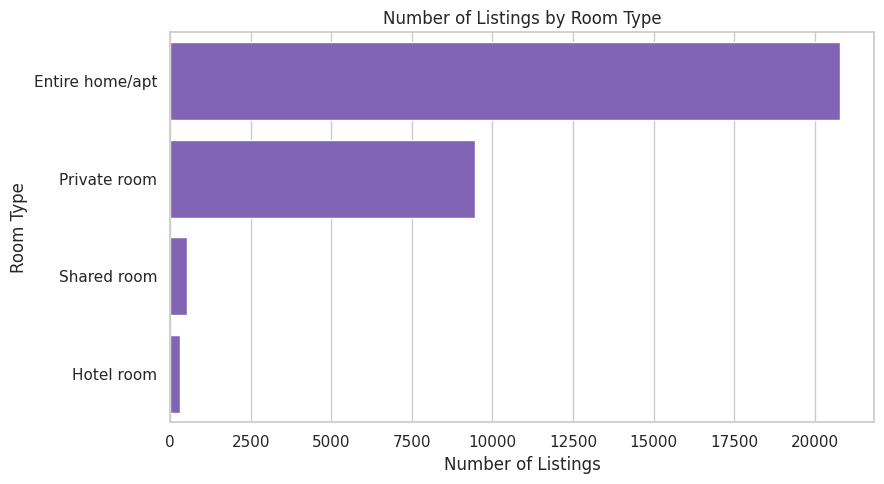

In [136]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=room_type_count,
    x="total_listings",
    y="room_type",
    color=purple
)

plt.title("Number of Listings by Room Type")
plt.xlabel("Number of Listings")
plt.ylabel("Room Type")
plt.tight_layout()
plt.show()

In [137]:
# Top 10 neighbourhoods by number of listings
top_neighbourhood = (
    df["neighbourhood"]
    .value_counts()
    .head(10)
    .reset_index()
)

top_neighbourhood.columns = ["neighbourhood", "total_listings"]
top_neighbourhood

,neighbourhood,total_listings
0,Vadhana,4504
1,Khlong Toei,3976
2,Huai Khwang,3974
3,Ratchathewi,1822
4,Sathon,1356
5,Phra Nakhon,1353
6,Phra Khanong,1150
7,Bang Rak,1135
8,Suanluang,919
9,Bang Na,894


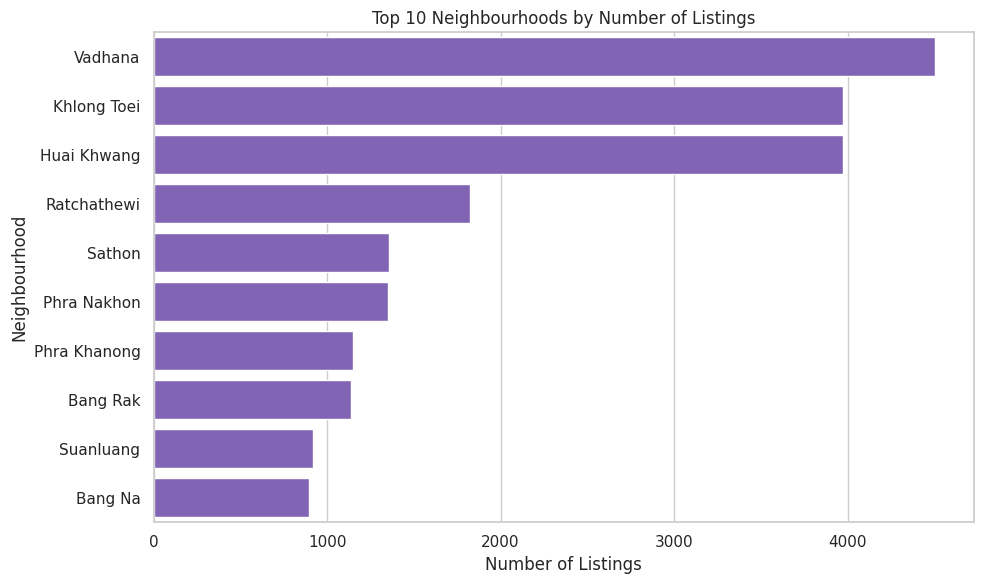

In [138]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_neighbourhood,
    x="total_listings",
    y="neighbourhood",
    color=purple
)

plt.title("Top 10 Neighbourhoods by Number of Listings")
plt.xlabel("Number of Listings")
plt.ylabel("Neighbourhood")
plt.tight_layout()
plt.show()

In [139]:
# Price by room type (valid prices only)
price_by_room = (
    df_price_eda
    .groupby("room_type", observed=True)
    .agg(
        total_listings=("id", "count"),
        median_price=("price", "median"),
        mean_price=("price", "mean")
    )
    .sort_values("median_price", ascending=False)
    .reset_index()
)

price_by_room

,room_type,total_listings,median_price,mean_price
0,Hotel room,274,1994.5,2616.116788
1,Entire home/apt,19194,1712.0,2548.929666
2,Private room,8874,1386.5,1950.932950
3,Shared room,497,432.0,660.400402


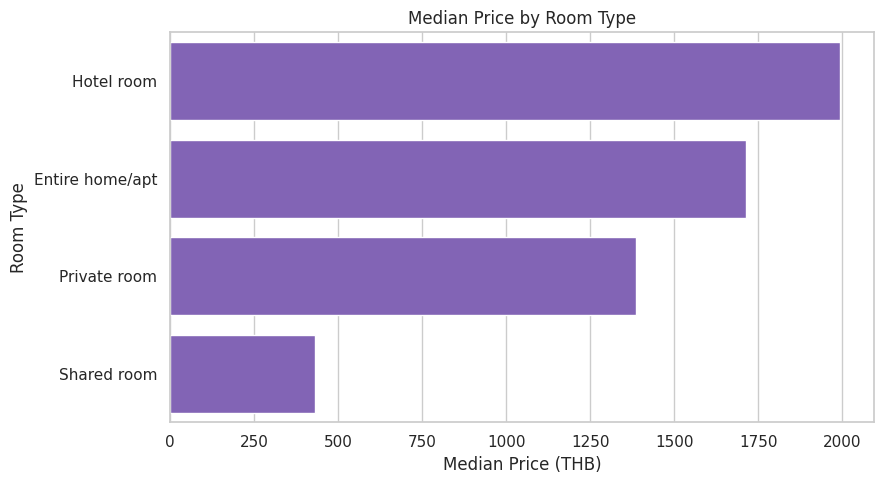

In [140]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=price_by_room,
    x="median_price",
    y="room_type",
    color=purple
)

plt.title("Median Price by Room Type")
plt.xlabel("Median Price (THB)")
plt.ylabel("Room Type")
plt.tight_layout()
plt.show()

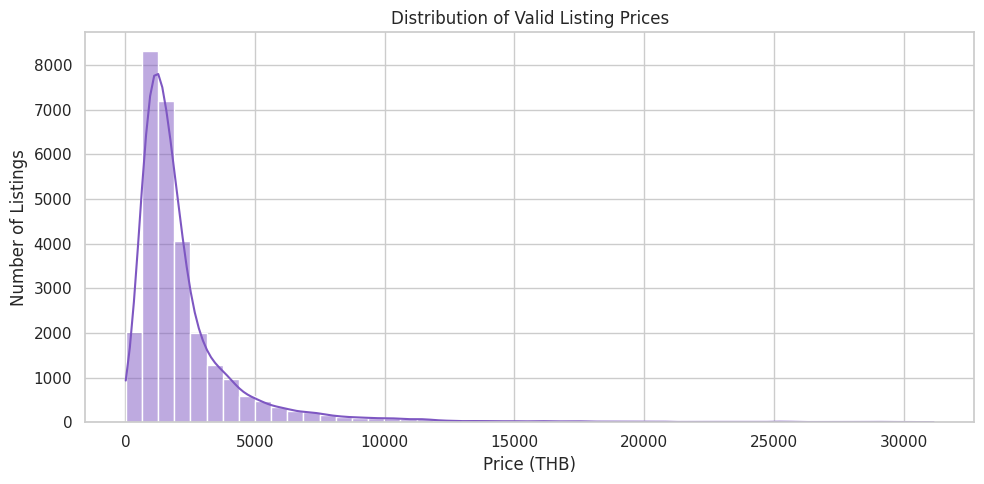

In [141]:
# Price distribution (valid prices)
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_price_eda,
    x="price",
    bins=50,
    color=purple,
    kde=True
)

plt.title("Distribution of Valid Listing Prices")
plt.xlabel("Price (THB)")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

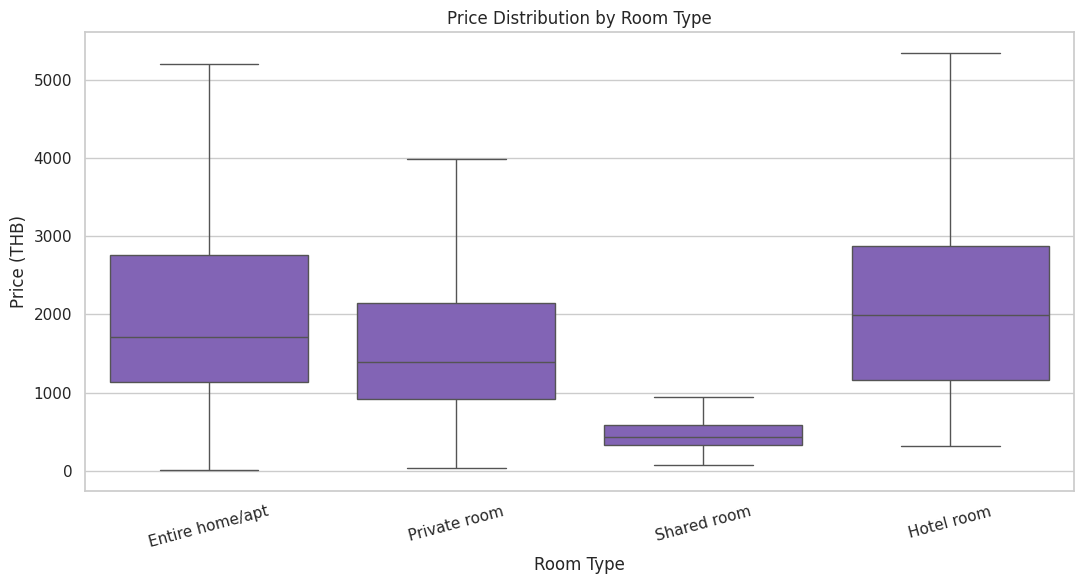

In [142]:
# Price spread by room type (outliers hidden for readability)
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df_price_eda,
    x="room_type",
    y="price",
    color=purple,
    showfliers=False
)

plt.title("Price Distribution by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Price (THB)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [143]:
# Most expensive neighbourhoods by median price
price_by_neighbourhood = (
    df_price_eda
    .groupby("neighbourhood")
    .agg(
        total_listings=("id", "count"),
        median_price=("price", "median")
    )
    .query("total_listings >= 20")
    .sort_values("median_price", ascending=False)
    .head(10)
    .reset_index()
)

price_by_neighbourhood

,neighbourhood,total_listings,median_price
0,Pathum Wan,684,2646.0
1,Vadhana,4123,2202.0
2,Lat Phrao,79,2182.0
3,Samphanthawong,305,2164.0
4,Bang Rak,1053,2043.0
5,Bueng Kum,249,2031.0
6,Khlong Toei,3682,1817.0
7,Pom Prap Sattru Phai,270,1755.0
8,Ratchathewi,1680,1744.0
9,Huai Khwang,3747,1686.0


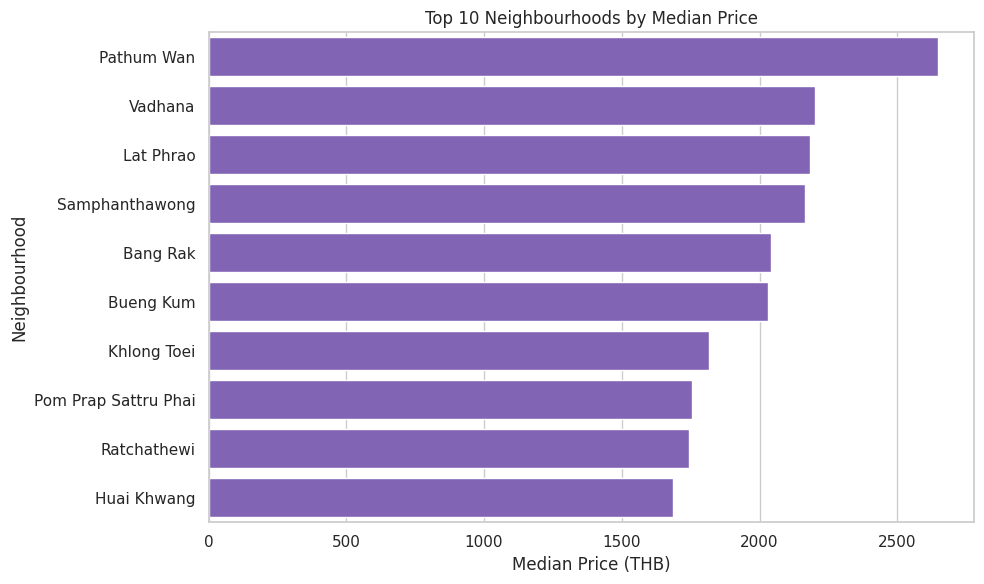

In [144]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=price_by_neighbourhood,
    x="median_price",
    y="neighbourhood",
    color=purple
)

plt.title("Top 10 Neighbourhoods by Median Price")
plt.xlabel("Median Price (THB)")
plt.ylabel("Neighbourhood")
plt.tight_layout()
plt.show()

In [145]:
# Review activity by room type
reviews_by_room = (
    df
    .groupby("room_type")
    .agg(
        total_listings=("id", "count"),
        median_reviews_ltm=("number_of_reviews_ltm", "median"),
        mean_reviews_per_month=("reviews_per_month", "mean"),
        listings_with_reviews=("number_of_reviews", lambda x: (x > 0).sum())
    )
    .reset_index()
)

reviews_by_room

,room_type,total_listings,median_reviews_ltm,mean_reviews_per_month,listings_with_reviews
0,Entire home/apt,20799,1.0,0.781076,14850
1,Hotel room,293,0.0,0.358601,249
2,Private room,9463,0.0,0.471876,5478
3,Shared room,512,0.0,0.226211,237


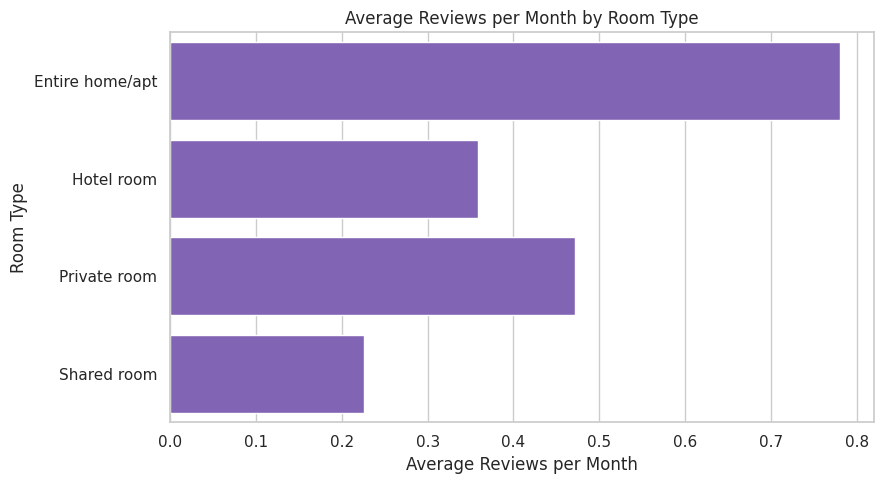

In [146]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=reviews_by_room,
    x="mean_reviews_per_month",
    y="room_type",
    color=purple
)

plt.title("Average Reviews per Month by Room Type")
plt.xlabel("Average Reviews per Month")
plt.ylabel("Room Type")
plt.tight_layout()
plt.show()

In [147]:
# Most active neighbourhoods by average reviews per month
review_by_neighbourhood = (
    df
    .groupby("neighbourhood")
    .agg(
        total_listings=("id", "count"),
        total_reviews_ltm=("number_of_reviews_ltm", "sum"),
        median_reviews_ltm=("number_of_reviews_ltm", "median"),
        mean_reviews_per_month=("reviews_per_month", "mean")
    )
    .query("total_listings >= 20")
    .sort_values("mean_reviews_per_month", ascending=False)
    .head(10)
    .reset_index()
)

review_by_neighbourhood

,neighbourhood,total_listings,total_reviews_ltm,median_reviews_ltm,mean_reviews_per_month
0,Pom Prap Sattru Phai,272,2930,3.0,1.022169
1,Bang Rak,1135,11279,2.0,1.016749
2,Lat Krabang,275,2757,0.0,0.924655
3,Khlong Toei,3976,32709,2.0,0.924424
4,Phaya Thai,519,5415,2.0,0.900482
5,Samphanthawong,315,2632,1.0,0.887460
6,Pathum Wan,754,5710,1.0,0.801658
7,Vadhana,4504,31450,2.0,0.790988
8,Khlong San,771,5236,2.0,0.766355
9,Ratchathewi,1822,10891,1.0,0.722563


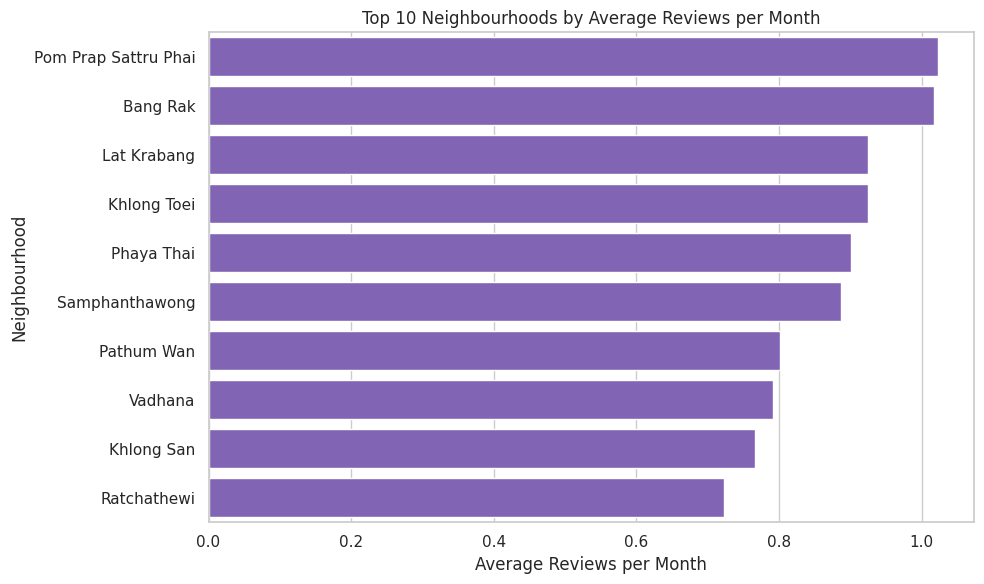

In [148]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=review_by_neighbourhood,
    x="mean_reviews_per_month",
    y="neighbourhood",
    color=purple
)

plt.title("Top 10 Neighbourhoods by Average Reviews per Month")
plt.xlabel("Average Reviews per Month")
plt.ylabel("Neighbourhood")
plt.tight_layout()
plt.show()

In [149]:
# Spearman rank correlation: robust to skewed prices
price_review_corr = df_price_eda[
    ["price", "number_of_reviews_ltm", "reviews_per_month"]
].corr(method="spearman")

price_review_corr

,price,number_of_reviews_ltm,reviews_per_month
price,1.000000,0.045462,0.053047
number_of_reviews_ltm,0.045462,1.000000,0.901659
reviews_per_month,0.053047,0.901659,1.000000


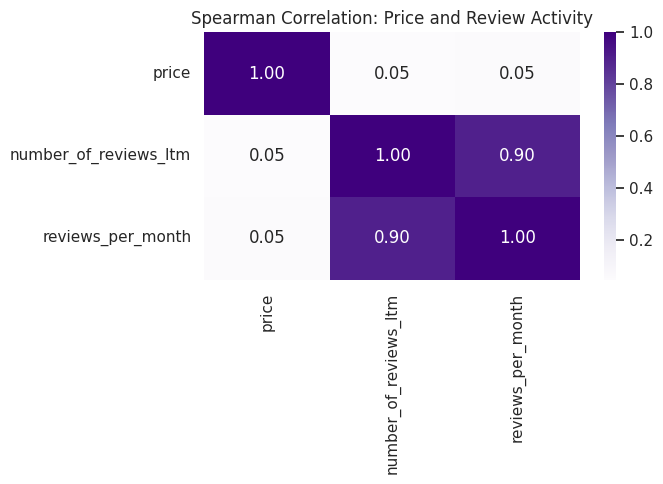

In [150]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    price_review_corr,
    annot=True,
    cmap="Purples",
    fmt=".2f"
)

plt.title("Spearman Correlation: Price and Review Activity")
plt.tight_layout()
plt.show()

In [151]:
# Listings and activity by minimum-stay category
stay_summary = (
    df
    .groupby("stay_category", observed=True)
    .agg(
        total_listings=("id", "count"),
        median_reviews_ltm=("number_of_reviews_ltm", "median"),
        mean_availability=("availability_365", "mean")
    )
    .reset_index()
)

stay_summary

,stay_category,total_listings,median_reviews_ltm,mean_availability
0,Short stay,21738,1.0,280.902429
1,Extended stay,5144,1.0,270.757582
2,Monthly/long stay,3843,0.0,260.974499
3,Very long stay,342,0.0,293.807018


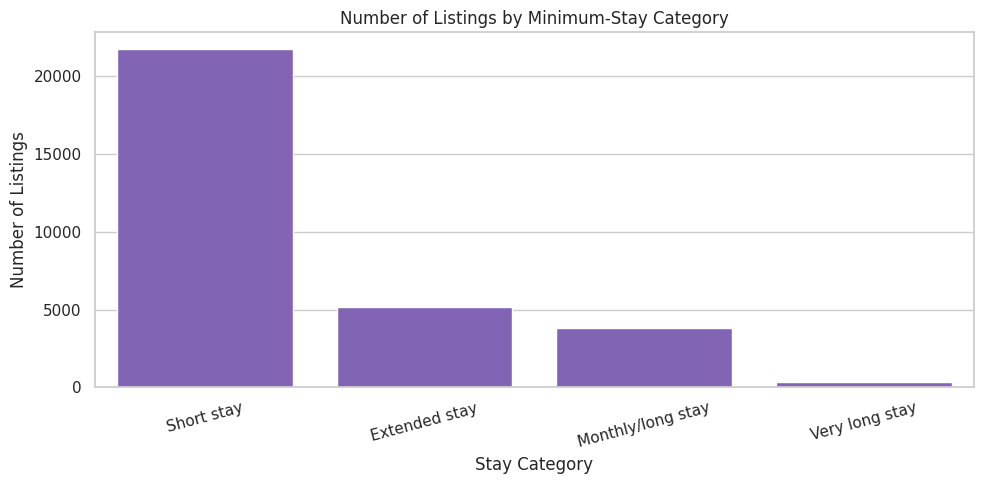

In [152]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=stay_summary,
    x="stay_category",
    y="total_listings",
    color=purple
)

plt.title("Number of Listings by Minimum-Stay Category")
plt.xlabel("Stay Category")
plt.ylabel("Number of Listings")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [153]:
# Listings per host
host_summary = (
    df
    .groupby("host_id")
    .agg(
        host_name=("host_name", "first"),
        total_listings=("id", "count"),
        total_reviews_ltm=("number_of_reviews_ltm", "sum")
    )
    .sort_values("total_listings", ascending=False)
)

host_summary.head(10)

,host_name,total_listings,total_reviews_ltm
host_id,,,
574804920,Jimmy,247,26
262132406,Loksu Baan,234,92
493412920,Alice,231,12
201677068,Curry,191,965
10005164,Sontana,182,485
434168399,Krittika,176,1
227771817,Zoom,171,173
705655935,Felicity,144,16
680424509,Jing,129,4


In [154]:
# Host segments by number of listings (exploratory; the SQL analysis uses its own 10+ listings "power host" threshold)
host_summary["host_category"] = pd.cut(
    host_summary["total_listings"],
    bins=[0, 1, 5, 20, float("inf")],
    labels=[
        "Individual",
        "Small host",
        "Professional host",
        "Large operator"
    ]
)

host_summary["host_category"].value_counts().sort_index()

,count
host_category,
Individual,4504
Small host,2339
Professional host,860
Large operator,231


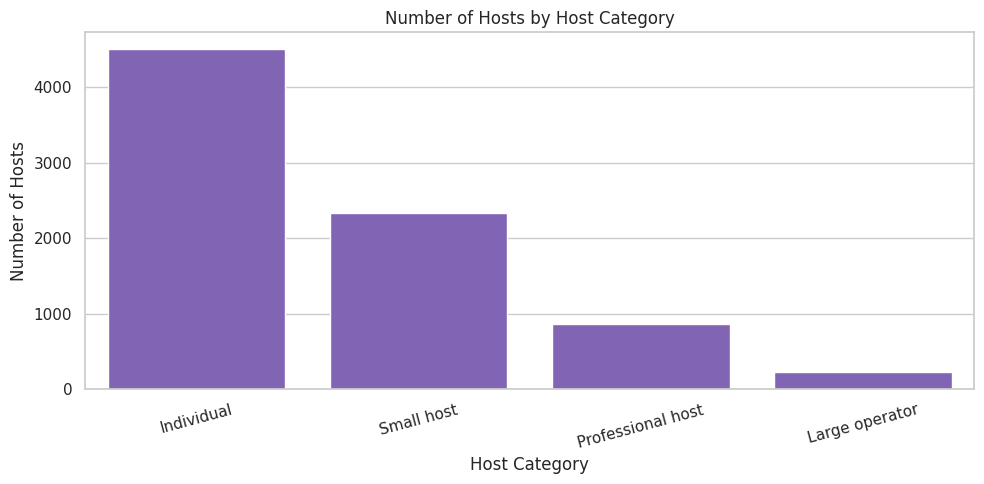

In [155]:
host_category_count = (
    host_summary["host_category"]
    .value_counts()
    .sort_index()
    .reset_index()
)

host_category_count.columns = ["host_category", "total_hosts"]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=host_category_count,
    x="host_category",
    y="total_hosts",
    color=purple
)

plt.title("Number of Hosts by Host Category")
plt.xlabel("Host Category")
plt.ylabel("Number of Hosts")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [156]:
# Supply vs demand proxy by neighbourhood (reviews per month as the proxy)
market_summary = (
    df
    .groupby("neighbourhood")
    .agg(
        total_listings=("id", "count"),
        mean_reviews_per_month=("reviews_per_month", "mean"),
        median_reviews_ltm=("number_of_reviews_ltm", "median")
    )
    .query("total_listings >= 20")
    .reset_index()
)

market_summary.head()

,neighbourhood,total_listings,mean_reviews_per_month,median_reviews_ltm
0,Bang Kapi,636,0.350142,0.0
1,Bang Khae,65,0.164000,0.0
2,Bang Khen,183,0.529071,0.0
3,Bang Kho Laem,224,0.521563,1.0
4,Bang Khun Thian,22,0.222273,0.0


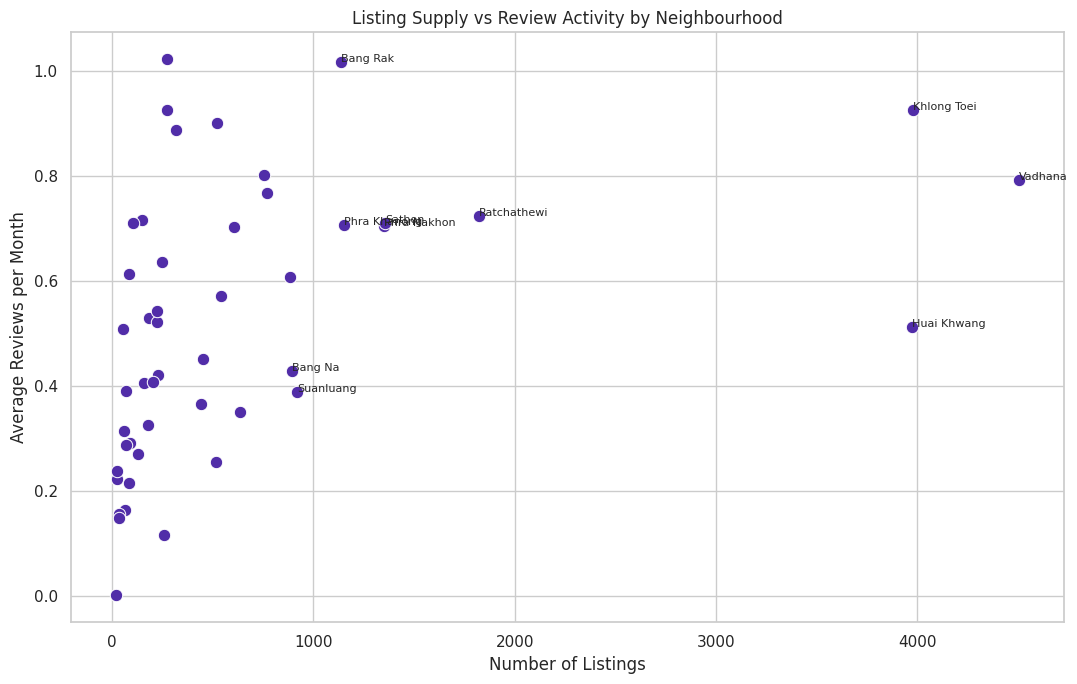

In [157]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=market_summary,
    x="total_listings",
    y="mean_reviews_per_month",
    color=purple_dark,
    s=80
)

for _, row in market_summary.nlargest(10, "total_listings").iterrows():
    plt.text(
        row["total_listings"],
        row["mean_reviews_per_month"],
        row["neighbourhood"],
        fontsize=8
    )

plt.title("Listing Supply vs Review Activity by Neighbourhood")
plt.xlabel("Number of Listings")
plt.ylabel("Average Reviews per Month")
plt.tight_layout()
plt.show()

In [158]:
# One summary table per neighbourhood, saved for later use
neighbourhood_summary = (
    df
    .groupby("neighbourhood")
    .agg(
        total_listings=("id", "count"),
        unique_hosts=("host_id", "nunique"),
        median_reviews_ltm=("number_of_reviews_ltm", "median"),
        mean_reviews_per_month=("reviews_per_month", "mean"),
        median_availability=("availability_365", "median")
    )
)

neighbourhood_price = (
    df_price_eda
    .groupby("neighbourhood")
    .agg(median_price=("price", "median"))
)

neighbourhood_summary = (
    neighbourhood_summary
    .join(neighbourhood_price)
    .sort_values("total_listings", ascending=False)
    .reset_index()
)

neighbourhood_summary.head(10)

,neighbourhood,total_listings,unique_hosts,median_reviews_ltm,mean_reviews_per_month,median_availability,median_price
0,Vadhana,4504,1445,2.0,0.790988,270.0,2202.0
1,Khlong Toei,3976,1154,2.0,0.924424,300.0,1817.0
2,Huai Khwang,3974,816,0.0,0.511346,359.0,1686.0
3,Ratchathewi,1822,544,1.0,0.722563,299.5,1744.0
4,Sathon,1356,419,1.0,0.710944,318.5,1399.0
5,Phra Nakhon,1353,262,0.0,0.704863,362.0,1348.0
6,Phra Khanong,1150,508,2.0,0.706930,320.0,1442.0
7,Bang Rak,1135,414,2.0,1.016749,297.0,2043.0
8,Suanluang,919,337,0.0,0.388770,362.0,1080.0
9,Bang Na,894,438,1.0,0.428702,347.5,1000.0


In [159]:
eda_output_path = (
    "/content/drive/MyDrive/Portofolio/"
    "neighbourhood_summary.csv"
)

neighbourhood_summary.to_csv(
    eda_output_path,
    index=False,
    encoding="utf-8-sig"
)

print("EDA saved:", eda_output_path)

EDA saved: /content/drive/MyDrive/Portofolio/neighbourhood_summary.csv
